# DX602 Final Project
## Exploratory Data Analysis of NHL Game Statistics (2000-2020)

---

**Author:** Jacob Benigeri  
**Date:** November 22nd 2026  
**Boston University Online Master of Data Science**  

## 1. Introduction

For my final project, I selected the Sports - NHL Game Statistics dataset. This dataset contains data from Martin Ellis NHL game data, version 2. This dataset contains data from 2000 to 2020. The dataset has 23,735 rows and 30 columns. Each observation represents one game. Some of the key variables include game dates, teams that played, offensive performance data (goals, shots), defensive and physical performance data (blocked shots, hits), special teams (power-play opportunities and goals), and game outcomes (wins, losses or draws).

The goal of my project is to conduct an exploratory data analysis (EDA) of historical NHL game statistics to better understand team performance. More specifically, I am interested in analyzing home advantage and the relationship between offensive, defensive, and special teams statistics and game outcomes. Furthermore, I aim to investigate how the game has evolved over time by looking at trends in scoring and other performance metrics. I also intend to examine the differences in performance across NHL teams. Finally, I will use linear regression to examine and model relationships between selected numerical variables.

Some of the questions I would like to examine are:
- Do home teams win more frequently and score more goals than away teams?
- What is more strongly associated with winning games: strong offensive performance or strong defensive performance?
- How are power-play and penalty-kill efficiency associated with game outcomes?
- How have scoring and other performance metrics evolved between 2000 and 2020?
- Which regular-season performance metrics are most strongly associated with playoff success?

## 2. Load and Inspect the Data

**2.1 Import Libraries**

In [1]:
# Import libraries required for analysis, including numpy in addition to those suggested in the instructions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk

plt.close("all")

**2.2 Load the Dataset**

In [2]:
# Loading the NHL Game Data (2000-2020) Dataset
game_stats = pd.read_csv("game_stats_v2.csv")

# Display the first five rows
game_stats.head(5)

,game_id,date_time_GMT,home_team,away_team,home_won,home_settled_in,home_head_coach,home_goals,home_shots,home_hits,...,away_goals,away_shots,away_hits,away_pim,away_powerPlayOpportunities,away_powerPlayGoals,away_faceOffWinPercentage,away_giveaways,away_takeaways,away_blocked
0,2016020045,2016-10-19T00:30:00Z,Chicago Blackhawks,Philadelphia Flyers,True,REG,Joel Quenneville,7.0,28.0,20.0,...,4.0,27.0,30.0,6.0,4.0,2.0,50.9,12.0,9.0,11.0
1,2017020812,2018-02-07T00:00:00Z,Buffalo Sabres,Anaheim Ducks,False,OT,Phil Housley,3.0,33.0,17.0,...,4.0,34.0,16.0,6.0,3.0,1.0,43.8,7.0,4.0,14.0
2,2015020314,2015-11-24T01:00:00Z,Winnipeg Jets,Colorado Avalanche,False,REG,Paul Maurice,1.0,21.0,22.0,...,4.0,29.0,17.0,9.0,3.0,1.0,45.7,13.0,5.0,20.0
3,2015020849,2016-02-17T00:00:00Z,Carolina Hurricanes,Winnipeg Jets,True,REG,Bill Peters,2.0,29.0,16.0,...,1.0,21.0,21.0,10.0,4.0,0.0,31.4,4.0,14.0,16.0
4,2017020586,2017-12-30T03:00:00Z,Anaheim Ducks,Calgary Flames,True,REG,Randy Carlyle,2.0,41.0,15.0,...,1.0,23.0,20.0,19.0,3.0,0.0,54.7,10.0,4.0,7.0


In [3]:
# Display the dataset's dimensions
print("Number of rows:", game_stats.shape[0])
print("Number of columns:", game_stats.shape[1])

Number of rows: 23735
Number of columns: 30


**2.3 Inspect Columns and Data Types**

In [4]:
# Display all column names in the dataset and their data types
game_stats.info()
game_stats.dtypes.value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 23735 entries, 0 to 23734
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   game_id                      23735 non-null  int64  
 1   date_time_GMT                23735 non-null  str    
 2   home_team                    23730 non-null  str    
 3   away_team                    23730 non-null  str    
 4   home_won                     23735 non-null  bool   
 5   home_settled_in              23735 non-null  str    
 6   home_head_coach              23721 non-null  str    
 7   home_goals                   23731 non-null  float64
 8   home_shots                   23731 non-null  float64
 9   home_hits                    21271 non-null  float64
 10  home_pim                     23731 non-null  float64
 11  home_powerPlayOpportunities  23731 non-null  float64
 12  home_powerPlayGoals          23731 non-null  float64
 13  home_faceOffWinPercentage  

float64    20
str         7
bool        2
int64       1
Name: count, dtype: int64

**2.4 Assess Data Quality**

In [5]:
 #Calculate missing-value counts and percentages
missing_values = pd.DataFrame({
    "Missing Values": game_stats.isna().sum(),
    "Missing Percentage": game_stats.isna().mean() * 100
})
# Round percentages 
missing_values["Missing Percentage"] = missing_values["Missing Percentage"].round(2)

# Sort by missing-value count and display
missing_values.sort_values("Missing Values", ascending=False)

,Missing Values,Missing Percentage
away_faceOffWinPercentage,11074,46.66
home_faceOffWinPercentage,11074,46.66
home_takeaways,2464,10.38
home_hits,2464,10.38
away_takeaways,2464,10.38
away_giveaways,2464,10.38
away_hits,2464,10.38
home_blocked,2464,10.38
home_giveaways,2464,10.38
away_blocked,2464,10.38


In [6]:
# Check for fully duplicated rows
print("Duplicate rows:", game_stats.duplicated().sum())

# Check for duplicate game IDs
print("Duplicate game IDs:", game_stats["game_id"].duplicated().sum())

# Count unique game IDs
print("Unique game IDs:", game_stats["game_id"].nunique())


Duplicate rows: 0
Duplicate game IDs: 0
Unique game IDs: 23735


In [7]:
# Examine the date range of the dataset
print("First game:", game_stats["date_time_GMT"].min())
print("Last game:", game_stats["date_time_GMT"].max())

First game: 2000-10-04T23:00:00Z
Last game: 2020-09-29T00:00:00Z


In [8]:
# Examine unique values in selected categorical variables
print("Home game outcomes:", game_stats["home_won"].unique())
print("Away game outcomes:", game_stats["away_won"].unique())

print("Home settlement types:", game_stats["home_settled_in"].unique())
print("Away settlement types:", game_stats["away_settled_in"].unique())

Home game outcomes: [ True False]
Away game outcomes: [False  True]
Home settlement types: <ArrowStringArray>
['REG', 'OT', 'tbc']
Length: 3, dtype: str
Away settlement types: <ArrowStringArray>
['REG', 'OT', 'tbc']
Length: 3, dtype: str


**2.5 Initial Observations**

The dataset contains 23,735 rows and 30 columns. It predominantly contains numerical variables. The dataset has twenty floats, one integer identifier, seven strings and two Booleans. There are no duplicate rows or game IDs, so this confirms one observation per game. This contradicts the metadata, which states that there is one row for each team in the game (two rows per game). 

The game dates, team names, coach names, and settlement categories are stored as strings, while any count-based statistics are stored as floats. The two Boolean variables indicate whether the home or away team won, and the integer variable represents the game ID. There are significant missing values for faceoff percentages (46.66%) and several defensive  and physical performance statistics (10.38%). The settlement categories differ from those described in the metadata, as the undocumented category 'tbc' is present, while the documented category 'SO' is absent. 

Our next steps in Section 3 are to investigate and handle the missing values, convert any relevant data types, and address any inconsistencies in the data.

## 3. Data Cleaning and Preparation

**3.1 Data Type Conversion**

In [9]:
# Create a working copy to preserve the original dataset, this can be used for comparisons later

game_stats_clean = game_stats.copy()

# Convert game timestamps to datetime
game_stats_clean["date_time_GMT"] = pd.to_datetime(
    game_stats_clean["date_time_GMT"], utc=True
)

# Convert Game IDs from integers to strings
game_stats_clean["game_id"] = game_stats_clean["game_id"].astype(str)

# Check the conversions
game_stats_clean[["date_time_GMT", "game_id"]].dtypes

date_time_GMT    datetime64[us, UTC]
game_id                          str
dtype: object

I created a copy to preserve the original dataset. I also converted timestamps to datetime format to facilitate temporal analysis and game identifiers from integers to strings.

**3.2 Game Classification and Filtering**

In [10]:
# Each game ID is structured like this YYYYTT####
# The season (e.g., 2017 represents 2017-18 season), followed by the game type (TT) where 02 is Regular Season, 03 is Playoffs, and 04 is All-Star
# '####' is the Game-specific ID

# Extract the starting year of each NHL season from the ID, as an integer for eventual sorting and grouping
game_stats_clean["season"] = game_stats_clean["game_id"].str[:4].astype(int)

# Extract the game type code from game ID
game_stats_clean["game_type"] = game_stats_clean["game_id"].str[4:6]

# Map game type codes to descriptive categories
game_type_mapping = {
    "02": "Regular Season",
    "03": "Playoffs",
    "04": "All-Star"
}

game_stats_clean["game_type"] = game_stats_clean["game_type"].map(game_type_mapping)

# Display distribution of game types and seasons
display(game_stats_clean["game_type"].value_counts(dropna=False))
display(game_stats_clean["season"].value_counts(dropna=False).sort_index())

game_type
Regular Season    22794
Playoffs            936
All-Star              5
Name: count, dtype: int64

season
2000    1230
2001    1230
2002    1230
2003    1230
2005    1230
2006    1230
2007    1230
2008    1230
2009    1230
2010    1319
2011    1316
2012     806
2013    1323
2014    1319
2015    1321
2016    1323
2017    1363
2018    1360
2019    1215
Name: count, dtype: int64

In [11]:
# Inspecting the All-Star games, since they are exhibition games
all_star_games = game_stats_clean[game_stats_clean["game_type"] == "All-Star"]

all_star_games

,game_id,date_time_GMT,home_team,away_team,home_won,home_settled_in,home_head_coach,home_goals,home_shots,home_hits,...,away_hits,away_pim,away_powerPlayOpportunities,away_powerPlayGoals,away_faceOffWinPercentage,away_giveaways,away_takeaways,away_blocked,season,game_type
21927,2019040651,2020-01-26 01:15:00+00:00,NaN,NaN,True,tbc,Bruce Cassidy,9.0,22.0,1.0,...,0.0,0.0,0.0,0.0,76.2,0.0,2.0,1.0,2019,All-Star
21928,2019040652,2020-01-26 02:15:00+00:00,NaN,NaN,False,tbc,Craig Berube,5.0,17.0,0.0,...,0.0,0.0,0.0,0.0,35.0,1.0,6.0,1.0,2019,All-Star
21929,2019040653,2020-01-26 03:15:00+00:00,NaN,NaN,True,tbc,Rick Tocchet,5.0,20.0,0.0,...,0.0,0.0,0.0,0.0,37.5,2.0,5.0,2.0,2019,All-Star
23145,2018040642,2019-01-27 02:15:00+00:00,NaN,NaN,False,tbc,Jon Cooper,4.0,20.0,0.0,...,0.0,0.0,0.0,0.0,56.2,2.0,6.0,1.0,2018,All-Star
23146,2018040643,2019-01-27 03:15:00+00:00,NaN,NaN,False,tbc,Paul Maurice,5.0,23.0,0.0,...,0.0,0.0,0.0,0.0,45.0,3.0,5.0,1.0,2018,All-Star


In [12]:
all_star_games[[
    "game_id",
    "date_time_GMT",
    "home_team",
    "away_team",
    "home_goals",
    "away_goals",
    "home_settled_in"
]]

,game_id,date_time_GMT,home_team,away_team,home_goals,away_goals,home_settled_in
21927,2019040651,2020-01-26 01:15:00+00:00,NaN,NaN,9.0,5.0,tbc
21928,2019040652,2020-01-26 02:15:00+00:00,NaN,NaN,5.0,10.0,tbc
21929,2019040653,2020-01-26 03:15:00+00:00,NaN,NaN,5.0,4.0,tbc
23145,2018040642,2019-01-27 02:15:00+00:00,NaN,NaN,4.0,7.0,tbc
23146,2018040643,2019-01-27 03:15:00+00:00,NaN,NaN,5.0,10.0,tbc


In [13]:
# Removing All-Star games from cleaned dataset
game_stats_clean = game_stats_clean[
    game_stats_clean["game_type"] != "All-Star"
].copy()

# Verifying the changes to game types

print("Cleaned dataset dimensions:", game_stats_clean.shape)

print("\nRemaining game types:")
print(game_stats_clean["game_type"].value_counts())

print("\nMissing team names:")
print(game_stats_clean[["home_team", "away_team"]].isna().sum())

Cleaned dataset dimensions: (23730, 32)

Remaining game types:
game_type
Regular Season    22794
Playoffs            936
Name: count, dtype: int64

Missing team names:
home_team    0
away_team    0
dtype: int64


I extracted the season and game type from the IDs, and looked at the NHL game ID encoding. I removed the five All-Star games because their exhibition format is not pertinent to the analysis I would like to conduct. 

**3.3 Missing Value Analysis**

In [14]:
# New updated missing-value counts and percentages
missing_values_clean = pd.DataFrame({
    "Missing Values": game_stats_clean.isna().sum(),
    "Missing Percentage": game_stats_clean.isna().mean() * 100
})

missing_values_clean["Missing Percentage"] = missing_values_clean["Missing Percentage"].round(2)

# Display the columns containing missing values
missing_values_clean[missing_values_clean["Missing Values"] > 0].sort_values(
    "Missing Values", ascending=False
)

,Missing Values,Missing Percentage
away_faceOffWinPercentage,11074,46.67
home_faceOffWinPercentage,11074,46.67
away_blocked,2464,10.38
home_blocked,2464,10.38
away_takeaways,2464,10.38
home_hits,2464,10.38
away_giveaways,2464,10.38
away_hits,2464,10.38
home_giveaways,2464,10.38
home_takeaways,2464,10.38


In [15]:
# Identify variables with corresponding home and away values
paired_stats = [
    "head_coach",
    "goals",
    "shots",
    "hits",
    "pim",
    "powerPlayOpportunities",
    "powerPlayGoals",
    "faceOffWinPercentage",
    "giveaways",
    "takeaways",
    "blocked"
]

# Compare missing-value patterns between home and away statistics
for stat in paired_stats:
    same_missing = game_stats_clean["home_" + stat].isna().equals(
        game_stats_clean["away_" + stat].isna()
    )
    print(stat, ":", same_missing)

head_coach : True
goals : True
shots : True
hits : True
pim : True
powerPlayOpportunities : True
powerPlayGoals : True
faceOffWinPercentage : True
giveaways : True
takeaways : True
blocked : True


In [16]:
# Select performance variables for historical analysis of missing values, if missing values are concentrated by season this changes future analysis
missing_stats = [
    "home_faceOffWinPercentage",
    "home_hits",
    "home_giveaways",
    "home_takeaways",
    "home_blocked",
    "home_goals",
    "home_shots",
    "home_pim",
    "home_powerPlayOpportunities",
    "home_powerPlayGoals",
    "home_head_coach"
]

# Calculate missing-value percentages by season
missing_by_season = (
    game_stats_clean[missing_stats]
    .isna()
    .groupby(game_stats_clean["season"])
    .mean() * 100
)

missing_by_season.round(2)

,home_faceOffWinPercentage,home_hits,home_giveaways,home_takeaways,home_blocked,home_goals,home_shots,home_pim,home_powerPlayOpportunities,home_powerPlayGoals,home_head_coach
season,,,,,,,,,,,
2000,100.00,100.00,100.00,100.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00
2001,100.00,100.00,100.00,100.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00
2002,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2003,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2005,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2006,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2007,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2008,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2009,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


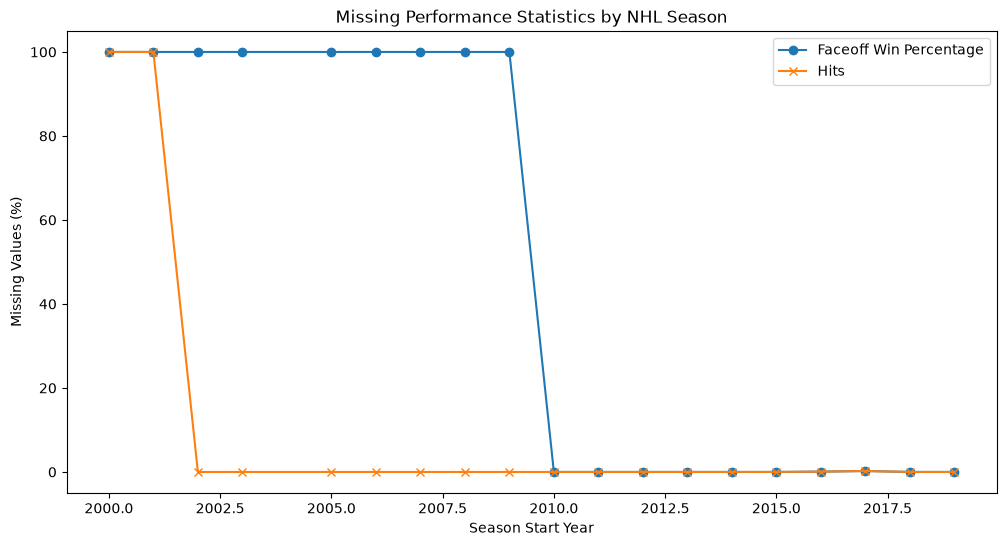

In [17]:
# Investigate missing-value percentages across NHL seasons
plt.figure(figsize=(12, 6))

plt.plot(
    missing_by_season.index,
    missing_by_season["home_faceOffWinPercentage"],
    marker="o",
    label="Faceoff Win Percentage"
)

plt.plot(
    missing_by_season.index,
    missing_by_season["home_hits"],
    marker="x",
    label="Hits"
)

plt.title("Missing Performance Statistics by NHL Season")
plt.xlabel("Season Start Year")
plt.ylabel("Missing Values (%)")
plt.legend()

In [18]:
# Investigate missing-value percentages by game type
missing_by_game_type = (
    game_stats_clean[missing_stats]
    .isna()
    .groupby(game_stats_clean["game_type"])
    .mean() * 100
)

missing_by_game_type.round(2).T

game_type,Playoffs,Regular Season
home_faceOffWinPercentage,0.43,48.57
home_hits,0.43,10.79
home_giveaways,0.43,10.79
home_takeaways,0.43,10.79
home_blocked,0.43,10.79
home_goals,0.43,0.00
home_shots,0.43,0.00
home_pim,0.43,0.00
home_powerPlayOpportunities,0.43,0.00
home_powerPlayGoals,0.43,0.00


In this section, I identified systematic historical missingness in faceoff win percentages and several defensive and physical performance statistics.

**3.4 Data Consistency and Validation**

In [19]:
# Examining the remaining settlement categories
display(game_stats_clean["home_settled_in"].value_counts())
display(game_stats_clean["away_settled_in"].value_counts())

# Check for identical settlement columns
print("Identical settlement columns:",
      game_stats_clean["home_settled_in"].equals(
          game_stats_clean["away_settled_in"]
      ))

home_settled_in
REG    18153
OT      5563
tbc       14
Name: count, dtype: int64

away_settled_in
REG    18153
OT      5563
tbc       14
Name: count, dtype: int64

Identical settlement columns: True


In [20]:
# Check games with the undocumented settlement category
tbc_games = game_stats_clean[
    game_stats_clean["home_settled_in"] == "tbc"
]

# These games are all playoff games, so they may be tbc because the series has been concluded
display(tbc_games[[
    "game_id",
    "season",
    "game_type",
    "date_time_GMT",
    "home_team",
    "away_team",
    "home_won",
    "away_won",
    "home_goals",
    "away_goals",
    "home_shots",
    "away_shots"
]].sort_values("game_id"))

,game_id,season,game_type,date_time_GMT,home_team,away_team,home_won,away_won,home_goals,away_goals,home_shots,away_shots
20671,2016030137,2016,Playoffs,2017-04-25 23:30:00+00:00,Washington Capitals,Toronto Maple Leafs,False,False,0.0,0.0,0.0,0.0
20830,2016030155,2016,Playoffs,2017-04-23 00:00:00+00:00,Chicago Blackhawks,Nashville Predators,False,False,0.0,0.0,0.0,0.0
20537,2016030175,2016,Playoffs,2017-04-22 02:00:00+00:00,Anaheim Ducks,Calgary Flames,False,False,0.0,0.0,0.0,0.0
20885,2016030217,2016,Playoffs,2017-05-11 23:30:00+00:00,Ottawa Senators,NY Rangers Rangers,False,False,NaN,NaN,NaN,NaN
20750,2016030327,2016,Playoffs,2017-05-25 01:00:00+00:00,Anaheim Ducks,Nashville Predators,False,False,0.0,0.0,0.0,0.0
20768,2016030417,2016,Playoffs,2017-06-15 00:00:00+00:00,Pittsburgh Penguins,Nashville Predators,False,False,0.0,0.0,0.0,0.0
20477,2017030175,2017,Playoffs,2018-04-20 02:00:00+00:00,Vegas Golden Knights,Los Angeles Kings,False,False,0.0,0.0,0.0,0.0
20452,2017030185,2017,Playoffs,2018-04-21 02:30:00+00:00,Anaheim Ducks,San Jose Sharks,False,False,NaN,NaN,NaN,NaN
20527,2017030227,2017,Playoffs,2018-05-09 23:30:00+00:00,Washington Capitals,Pittsburgh Penguins,False,False,0.0,0.0,0.0,0.0
20447,2017030247,2017,Playoffs,2018-05-09 01:00:00+00:00,Vegas Golden Knights,San Jose Sharks,False,False,0.0,0.0,0.0,0.0


In [21]:
# These are all playoff games, I want to check whether all these series were concluded at this point
for game_id in tbc_games["game_id"]:
    earlier_games = game_stats_clean[
        (game_stats_clean["game_id"].str[:-1] == game_id[:-1]) &
        (game_stats_clean["game_id"] < game_id)
    ]

    winners = pd.concat([
        earlier_games.loc[earlier_games["home_won"], "home_team"],
        earlier_games.loc[earlier_games["away_won"], "away_team"]
    ])

    print(game_id, winners.value_counts().max() == 4)

2017030247 True
2017030185 True
2017030175 True
2017030326 True
2017030327 True
2017030416 True
2017030417 True
2017030227 True
2016030175 True
2016030137 True
2016030327 True
2016030417 True
2016030155 True
2016030217 True


In [22]:
# Remove all these games, since they were never played due to the series having concluded
game_stats_clean = game_stats_clean[
    ~game_stats_clean["game_id"].isin(tbc_games["game_id"])
].copy()

print(game_stats_clean.shape)
display(game_stats_clean["game_type"].value_counts())

(23716, 32)


game_type
Regular Season    22794
Playoffs            922
Name: count, dtype: int64

In [23]:
# Examine home and away outcomes
display(pd.crosstab(
    game_stats_clean["home_won"],
    game_stats_clean["away_won"]
))

# Investigate games where neither team won
tied_games = game_stats_clean[
    (~game_stats_clean["home_won"]) &
    (~game_stats_clean["away_won"])
]

display(tied_games["season"].value_counts().sort_index())

print("All scores equal:",
      (tied_games["home_goals"] == tied_games["away_goals"]).all())

away_won,False,True
home_won,,
False,628,10408
True,12680,0


season
2000    152
2001    149
2002    157
2003    170
Name: count, dtype: int64

All scores equal: True


In [24]:
# Check if winning teams scored fewer goals than their opponents
for side, opponent in [("home", "away"), ("away", "home")]:
    print(side, "winners with fewer goals:",
          (game_stats_clean[side + "_won"] &
           (game_stats_clean[side + "_goals"] <
            game_stats_clean[opponent + "_goals"])).sum())

# Investigate score ties with a recorded winner
equal_score_winners = game_stats_clean[
    (game_stats_clean["home_goals"] == game_stats_clean["away_goals"]) &
    (game_stats_clean["home_won"] | game_stats_clean["away_won"])
]

display(equal_score_winners["home_settled_in"].value_counts())

home winners with fewer goals: 0
away winners with fewer goals: 0


home_settled_in
OT    2067
Name: count, dtype: int64

In [25]:
# Check for any invalid numerical statistics
print("Negative values:", (game_stats_clean.select_dtypes(include="number") < 0).sum().sum())

for side in ["home", "away"]:
    print(side, "goals exceeding shots:",
          (game_stats_clean[side + "_goals"] > game_stats_clean[side + "_shots"]).sum())

    print(side, "zero shots:",
          (game_stats_clean[side + "_shots"] == 0).sum())

Negative values: 0
home goals exceeding shots: 0
home zero shots: 0
away goals exceeding shots: 0
away zero shots: 0


In [26]:
# Inspect unique team names
team_names = pd.concat([game_stats_clean["home_team"], 
                        game_stats_clean["away_team"]]).unique()

print("Number of teams:", len(team_names))
print(sorted(team_names))

Number of teams: 33
['Anaheim Ducks', 'Arizona Coyotes', 'Atlanta Thrashers', 'Boston Bruins', 'Buffalo Sabres', 'Calgary Flames', 'Carolina Hurricanes', 'Chicago Blackhawks', 'Colorado Avalanche', 'Columbus Blue Jackets', 'Dallas Stars', 'Detroit Red Wings', 'Edmonton Oilers', 'Florida Panthers', 'Los Angeles Kings', 'Minnesota Wild', 'Montreal Canadiens', 'NY Islanders Islanders', 'NY Rangers Rangers', 'Nashville Predators', 'New Jersey Devils', 'Ottawa Senators', 'Philadelphia Flyers', 'Phoenix Coyotes', 'Pittsburgh Penguins', 'San Jose Sharks', 'St Louis Blues', 'Tampa Bay Lightning', 'Toronto Maple Leafs', 'Vancouver Canucks', 'Vegas Golden Knights', 'Washington Capitals', 'Winnipeg Jets']


This section was the most crucial. I removed 14 unplayed playoff games after confirming their respective series had already concluded. I retained 628 legitimate draws and 2,067 equal-score games with recorded winners. The numerical validation checks also showed no violations of the tested conditions.

**3.5 Handling Missing Values**

In [27]:
# Display missing values after removing unplayed playoff games
remaining_missing = pd.DataFrame({
    "Missing Values": game_stats_clean.isna().sum(),
    "Missing Percentage": (game_stats_clean.isna().mean() * 100).round(2)
})

# Display any variables with remaining missing values
display(remaining_missing[remaining_missing["Missing Values"] > 0])

,Missing Values,Missing Percentage
home_hits,2460,10.37
home_faceOffWinPercentage,11070,46.68
home_giveaways,2460,10.37
home_takeaways,2460,10.37
home_blocked,2460,10.37
away_hits,2460,10.37
away_faceOffWinPercentage,11070,46.68
away_giveaways,2460,10.37
away_takeaways,2460,10.37
away_blocked,2460,10.37


I retained historical missing values to avoid unnecessary data loss and misleading imputation. Missing observations will be excluded depending on the analysis being conducted, and the missing-value analysis conducted in this section will be used to inform those decisions in future sections.

**3.6 Column Names and Redundancy**

In [28]:
# New column names
column_mapping = {
    "date_time_GMT": "date_time_utc",
    "home_powerPlayOpportunities": "home_power_play_opportunities",
    "away_powerPlayOpportunities": "away_power_play_opportunities",
    "home_powerPlayGoals": "home_power_play_goals",
    "away_powerPlayGoals": "away_power_play_goals",
    "home_faceOffWinPercentage": "home_faceoff_win_percentage",
    "away_faceOffWinPercentage": "away_faceoff_win_percentage",
    "home_pim": "home_penalty_minutes",
    "away_pim": "away_penalty_minutes",
    "home_blocked": "home_blocked_shots",
    "away_blocked": "away_blocked_shots"
}

game_stats_clean = game_stats_clean.rename(columns=column_mapping)

In [29]:
# Removing the redundant settlement column
game_stats_clean = game_stats_clean.drop(columns=["away_settled_in"])

game_stats_clean = game_stats_clean.rename(
    columns={"home_settled_in": "settled_in"}
)

In [30]:
# Fixing team naming inconsistencies
team_mapping = {
    "NY Islanders Islanders": "New York Islanders",
    "NY Rangers Rangers": "New York Rangers",
    "St Louis Blues": "St. Louis Blues"
}

for side in ["home", "away"]:
    game_stats_clean[side + "_team"] = game_stats_clean[side + "_team"].replace(team_mapping)

# Verify cleaned dataset dimensions and column names
print("Dataset dimensions:", game_stats_clean.shape)
display(game_stats_clean.columns)

Dataset dimensions: (23716, 31)


Index(['game_id', 'date_time_utc', 'home_team', 'away_team', 'home_won',
       'settled_in', 'home_head_coach', 'home_goals', 'home_shots',
       'home_hits', 'home_penalty_minutes', 'home_power_play_opportunities',
       'home_power_play_goals', 'home_faceoff_win_percentage',
       'home_giveaways', 'home_takeaways', 'home_blocked_shots', 'away_won',
       'away_head_coach', 'away_goals', 'away_shots', 'away_hits',
       'away_penalty_minutes', 'away_power_play_opportunities',
       'away_power_play_goals', 'away_faceoff_win_percentage',
       'away_giveaways', 'away_takeaways', 'away_blocked_shots', 'season',
       'game_type'],
      dtype='str')

Here, I standardized the column names, removed the redundant settlement column, and corrected the team naming inconsistencies while preserving their historical team identities.

**3.7 Final Cleaned Dataset**

In [31]:
# Check the final cleaned dataset
print("Original dataset dimensions:", game_stats.shape)
print("Cleaned dataset dimensions:", game_stats_clean.shape)
print("Rows removed:", len(game_stats) - len(game_stats_clean))
print("Duplicate game IDs:", game_stats_clean["game_id"].duplicated().sum())

# Check game types and team names
display(game_stats_clean["game_type"].value_counts())

display(sorted(pd.concat([
    game_stats_clean["home_team"],
    game_stats_clean["away_team"]
]).unique()))

# Display the cleaned dataset
game_stats_clean.head()

Original dataset dimensions: (23735, 30)
Cleaned dataset dimensions: (23716, 31)
Rows removed: 19
Duplicate game IDs: 0


game_type
Regular Season    22794
Playoffs            922
Name: count, dtype: int64

['Anaheim Ducks',
 'Arizona Coyotes',
 'Atlanta Thrashers',
 'Boston Bruins',
 'Buffalo Sabres',
 'Calgary Flames',
 'Carolina Hurricanes',
 'Chicago Blackhawks',
 'Colorado Avalanche',
 'Columbus Blue Jackets',
 'Dallas Stars',
 'Detroit Red Wings',
 'Edmonton Oilers',
 'Florida Panthers',
 'Los Angeles Kings',
 'Minnesota Wild',
 'Montreal Canadiens',
 'Nashville Predators',
 'New Jersey Devils',
 'New York Islanders',
 'New York Rangers',
 'Ottawa Senators',
 'Philadelphia Flyers',
 'Phoenix Coyotes',
 'Pittsburgh Penguins',
 'San Jose Sharks',
 'St. Louis Blues',
 'Tampa Bay Lightning',
 'Toronto Maple Leafs',
 'Vancouver Canucks',
 'Vegas Golden Knights',
 'Washington Capitals',
 'Winnipeg Jets']

,game_id,date_time_utc,home_team,away_team,home_won,settled_in,home_head_coach,home_goals,home_shots,home_hits,...,away_hits,away_penalty_minutes,away_power_play_opportunities,away_power_play_goals,away_faceoff_win_percentage,away_giveaways,away_takeaways,away_blocked_shots,season,game_type
0,2016020045,2016-10-19 00:30:00+00:00,Chicago Blackhawks,Philadelphia Flyers,True,REG,Joel Quenneville,7.0,28.0,20.0,...,30.0,6.0,4.0,2.0,50.9,12.0,9.0,11.0,2016,Regular Season
1,2017020812,2018-02-07 00:00:00+00:00,Buffalo Sabres,Anaheim Ducks,False,OT,Phil Housley,3.0,33.0,17.0,...,16.0,6.0,3.0,1.0,43.8,7.0,4.0,14.0,2017,Regular Season
2,2015020314,2015-11-24 01:00:00+00:00,Winnipeg Jets,Colorado Avalanche,False,REG,Paul Maurice,1.0,21.0,22.0,...,17.0,9.0,3.0,1.0,45.7,13.0,5.0,20.0,2015,Regular Season
3,2015020849,2016-02-17 00:00:00+00:00,Carolina Hurricanes,Winnipeg Jets,True,REG,Bill Peters,2.0,29.0,16.0,...,21.0,10.0,4.0,0.0,31.4,4.0,14.0,16.0,2015,Regular Season
4,2017020586,2017-12-30 03:00:00+00:00,Anaheim Ducks,Calgary Flames,True,REG,Randy Carlyle,2.0,41.0,15.0,...,20.0,19.0,3.0,0.0,54.7,10.0,4.0,7.0,2017,Regular Season


After cleaning, 23,716 observations and 31 variables were retained for my analysis. This represents 99.92% of the original observations, demonstrating that the cleaning process preserved nearly all available games. Further filtering may be required depending on which variables are needed for subsequent analysis.

## 4. Descriptive Statistics

**4.1 Numerical Summary Statistics**

In [32]:
# Isolate numerical performance variables, excluding the season identifier
numerical_stats = game_stats_clean.select_dtypes(include="number").drop(columns=["season"])

# Display descriptive statistics for numerical performance variables
display(numerical_stats.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
home_goals,23716.0,2.90,1.68,0.0,2.0,3.0,4.0,12.0
home_shots,23716.0,30.67,6.88,6.0,26.0,30.0,35.0,88.0
home_hits,21256.0,21.80,9.18,0.0,16.0,21.0,27.0,80.0
home_penalty_minutes,23716.0,11.75,9.05,0.0,6.0,10.0,15.0,213.0
home_power_play_opportunities,23716.0,3.94,1.94,0.0,3.0,4.0,5.0,15.0
home_power_play_goals,23716.0,0.73,0.85,0.0,0.0,1.0,1.0,6.0
home_faceoff_win_percentage,12646.0,51.61,7.02,24.1,46.9,51.7,56.4,79.2
home_giveaways,21256.0,10.02,5.72,0.0,6.0,9.0,13.0,52.0
home_takeaways,21256.0,7.56,4.41,0.0,5.0,7.0,10.0,40.0
home_blocked_shots,21256.0,12.93,5.55,0.0,9.0,13.0,16.0,40.0


Home teams average more goals (2.90 vs. 2.62) and more shots on goal (30.67 vs. 28.90) than away teams, showing some evidence of home advantage. They also average more power-play opportunities and power-play goals, while recording fewer penalty minutes. Away teams average slightly more blocked shots (13.51 vs. 12.93), which may suggest that they face greater offensive pressure from the home teams. Some variables have high maximum values, such as shots (88) and penalty minutes (213), which warrant further examination. Observation counts vary between 12,646 and 23,716 due to historical missingness identified in Section 3. 

**4.2 Categorical Summary Statistics**

In [33]:
# Select most pertinent categorical and Boolean variables
categorical_stats = game_stats_clean[[
    "home_team", "away_team", "home_won",
    "away_won", "settled_in", "game_type"
]]

# Display categorical summary statistics
display(categorical_stats.describe(include="all").T)

,count,unique,top,freq
home_team,23716,33,Boston Bruins,821
away_team,23716,33,Boston Bruins,812
home_won,23716,2,True,12680
away_won,23716,2,False,13308
settled_in,23716,2,REG,18153
game_type,23716,2,Regular Season,22794


In [34]:
# Display frequencies and percentages for the selected categorical variables
for column in ["home_won", "away_won", "settled_in", "game_type"]:
    print(column)

    display(pd.DataFrame({
        "Count": game_stats_clean[column].value_counts(),
        "Percentage": (game_stats_clean[column].value_counts(normalize=True) * 100).round(2)
    }))

home_won


,Count,Percentage
home_won,,
True,12680,53.47
False,11036,46.53


away_won


,Count,Percentage
away_won,,
False,13308,56.11
True,10408,43.89


settled_in


,Count,Percentage
settled_in,,
REG,18153,76.54
OT,5563,23.46


game_type


,Count,Percentage
game_type,,
Regular Season,22794,96.11
Playoffs,922,3.89


This dataset contains 33 distinct historical team names. The Boston Bruins are the most frequently represented team in both home and away observations. There is additional evidence of home advantage, as home teams won 53.47% of their games, compared to 43.89% for away teams, with 2.65% ending in draws. 76.54% of the games ended in regulation time and 23.46% were classified overtime, a category that appears to include shootouts. Regular-season games account for 96.11% of observations, and compared to only 3.89% for playoff games (All-Star games have been removed).

**4.3 Initial Observations**

These descriptive statistics have already provided preliminary evidence of home advantage in both offensive performance and game outcomes. Additional analysis is needed to determine which offensive, defensive, and special teams statistics are most strongly associated with winning in regular-season and playoff games. The historical missingness and the unequal representation of regular-season and playoff games must be considered in upcoming sections.

## 5. Numerical Data Visualizations

**5.1 Offensive Performance**

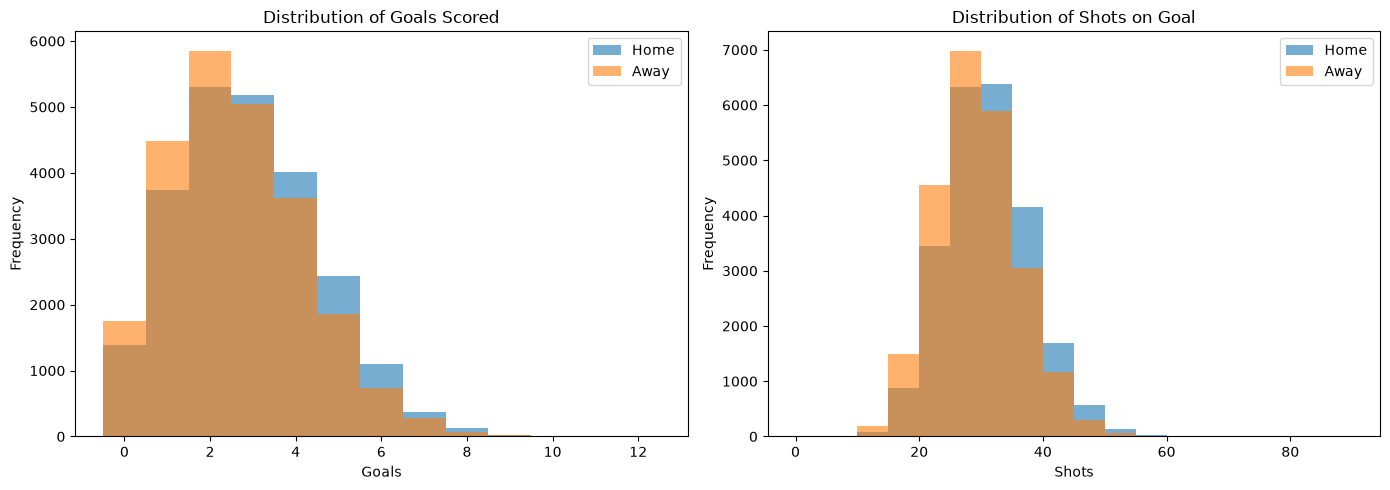

In [38]:
# Visualize distribution of goals and shots for home and away teams
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Goals
bins_goals = np.arange(0, numerical_stats[["home_goals", "away_goals"]].max().max() + 2) - 0.5

ax[0].hist(game_stats_clean["home_goals"], bins=bins_goals, alpha=0.6, label="Home")
ax[0].hist(game_stats_clean["away_goals"], bins=bins_goals, alpha=0.6, label="Away")
ax[0].set_title("Distribution of Goals Scored")
ax[0].set_xlabel("Goals")
ax[0].set_ylabel("Frequency")
ax[0].legend()

# Shots
bins_shots = np.arange(0, numerical_stats[["home_shots", "away_shots"]].max().max() + 5, 5)

ax[1].hist(game_stats_clean["home_shots"], bins=bins_shots, alpha=0.6, label="Home")
ax[1].hist(game_stats_clean["away_shots"], bins=bins_shots, alpha=0.6, label="Away")
ax[1].set_title("Distribution of Shots on Goal")
ax[1].set_xlabel("Shots")
ax[1].set_ylabel("Frequency")
ax[1].legend()

plt.tight_layout()
plt.show()

The distribution of goals scored is right-skewed, with most observations are concentrated between one and four goals. Two is the most frequent number of goals for both home and away teams. The shots on goal histogram is more bell-shaped then the distribution of goals, with a slight right skew. Both histograms show more shots and goals respectively for home teams so they show home advantage. However, there is substantial overlap between home and away distributions.

**5.2 Defensive and Special Teams Performance**

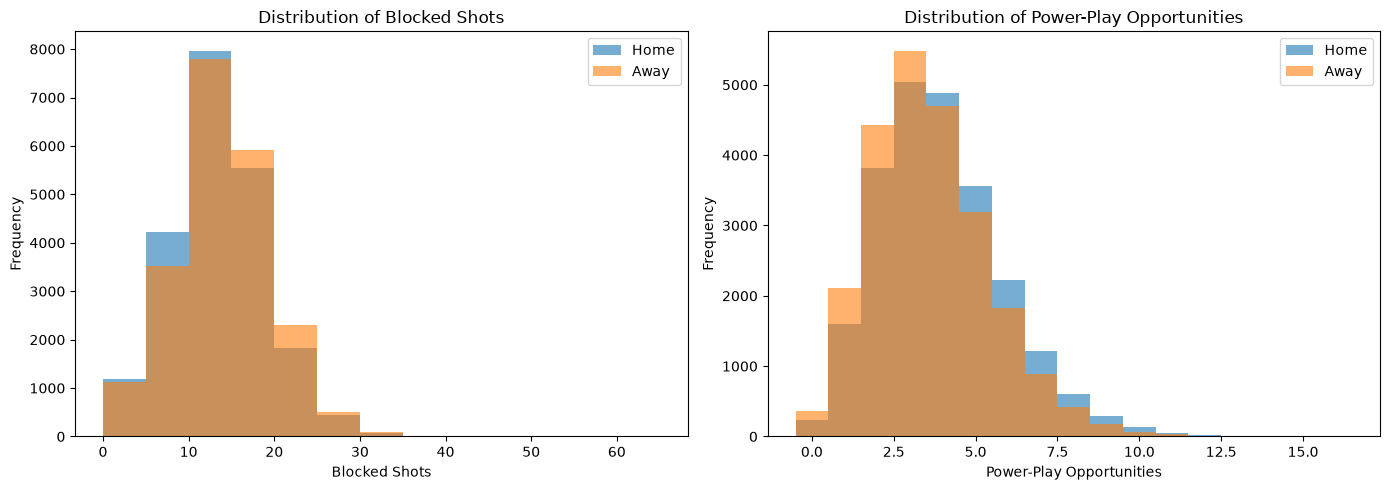

In [39]:
# Visualize defensive and special teams data
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Blocked shots
bins_blocked = np.arange(0, numerical_stats[["home_blocked_shots", "away_blocked_shots"]].max().max() + 5, 5)

ax[0].hist(game_stats_clean["home_blocked_shots"].dropna(), bins=bins_blocked, alpha=0.6, label="Home")
ax[0].hist(game_stats_clean["away_blocked_shots"].dropna(), bins=bins_blocked, alpha=0.6, label="Away")
ax[0].set_title("Distribution of Blocked Shots")
ax[0].set_xlabel("Blocked Shots")
ax[0].set_ylabel("Frequency")
ax[0].legend()

# Power-play opportunities
bins_pp = np.arange(0, numerical_stats[["home_power_play_opportunities", "away_power_play_opportunities"]].max().max() + 2) - 0.5

ax[1].hist(game_stats_clean["home_power_play_opportunities"], bins=bins_pp, alpha=0.6, label="Home")
ax[1].hist(game_stats_clean["away_power_play_opportunities"], bins=bins_pp, alpha=0.6, label="Away")
ax[1].set_title("Distribution of Power-Play Opportunities")
ax[1].set_xlabel("Power-Play Opportunities")
ax[1].set_ylabel("Frequency")
ax[1].legend()

plt.tight_layout()
plt.show()

The histogram of blocked shot shows a right-skewed distribution with the most frequent interval being the 10-14 range for both home and away teams. Away teams tend to record more blocked shots, which may suggest that they face greater offensive pressure rather than just being better defensively. 

Power-play opportunities have a right-skewed distribution with home teams tending to receive more opportunities. On the other hand, receiving more opportunities does not necessarily indicate greater power-play efficiency.

**5.3 Variability and Outliers**

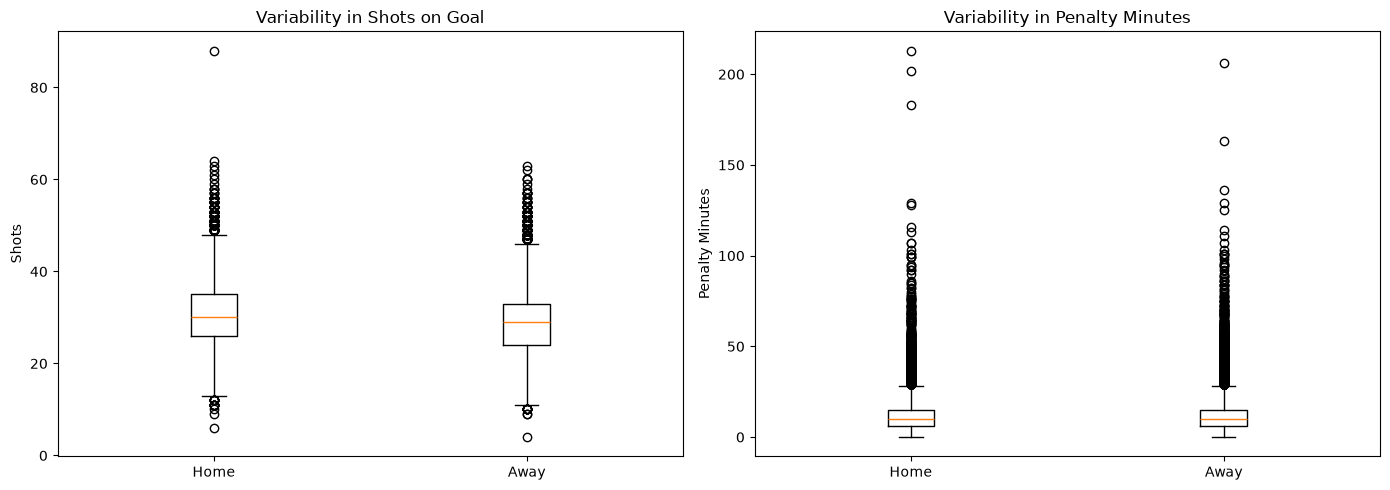

,Median,Q1,Q3,IQR
home_shots,30.0,26.0,35.0,9.0
away_shots,29.0,24.0,33.0,9.0
home_penalty_minutes,10.0,6.0,15.0,9.0
away_penalty_minutes,10.0,6.0,15.0,9.0


In [42]:
# Visualize variability and outliers in shots and penalty minutes
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Shots on goal
ax[0].boxplot([
    game_stats_clean["home_shots"],
    game_stats_clean["away_shots"]
])

ax[0].set_xticks([1, 2], ["Home", "Away"])
ax[0].set_title("Variability in Shots on Goal")
ax[0].set_ylabel("Shots")

# Penalty minutes
ax[1].boxplot([
    game_stats_clean["home_penalty_minutes"],
    game_stats_clean["away_penalty_minutes"]
])

ax[1].set_xticks([1, 2], ["Home", "Away"])
ax[1].set_title("Variability in Penalty Minutes")
ax[1].set_ylabel("Penalty Minutes")

plt.tight_layout()
plt.show()

# Calculate median and interquartile range (IQR)
boxplot_stats = numerical_stats[[
    "home_shots", "away_shots",
    "home_penalty_minutes", "away_penalty_minutes"
]]

summary = pd.DataFrame({
    "Median": boxplot_stats.median(),
    "Q1": boxplot_stats.quantile(0.25),
    "Q3": boxplot_stats.quantile(0.75),
    "IQR": boxplot_stats.quantile(0.75) - boxplot_stats.quantile(0.25)
})

display(summary)

Home teams have a marginally higher median number of shots on goal (30 vs. 29), they both have identical interquartile ranges. Both home and away teams have a median of 10 penalty minutes and identical interquartile ranges. This measure has numerous upper outliers though, with a substantial right skew. Extreme values are noticeable for home shots (88) and penalty minutes (213 for home teams and 206 for away teams). These observations are retained because a statistical outlier does not necessarily indicate a data error.

## 6. Categorical Data Analysis

**6.1 Game Outcomes and Home Advantage**

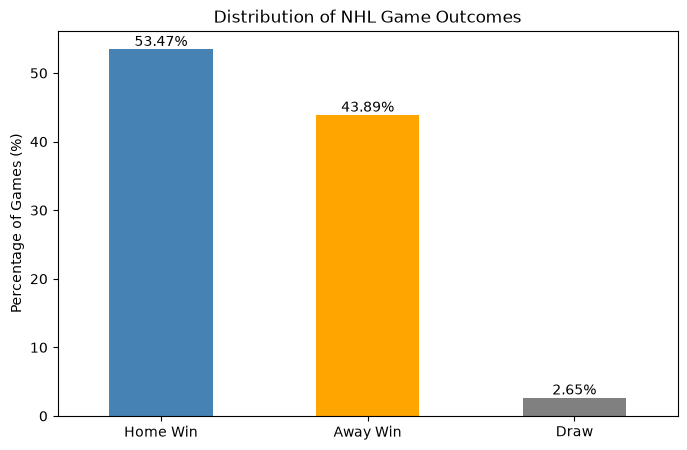

In [45]:
# Calculate game outcome percentages
outcomes = pd.Series({
    "Home Win": game_stats_clean["home_won"].mean() * 100,
    "Away Win": game_stats_clean["away_won"].mean() * 100,
    "Draw": (~game_stats_clean["home_won"] & ~game_stats_clean["away_won"]).mean() * 100
})

# Visualize game outcome percentages
ax = outcomes.plot(kind="bar", figsize=(8, 5), color=["steelblue", "orange", "grey"])

ax.set_title("Distribution of NHL Game Outcomes")
ax.set_ylabel("Percentage of Games (%)")
ax.set_xticklabels(outcomes.index, rotation=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%")

plt.show()

Home teams won 53.47% of their games, compared to 43.89% for away teams. This is a difference of 9.58 percentage points. This is consistent with the offensive performance distributions examined in Section 5. Historical draws account for approximately 2.65% of games. Further grouped analysis will help us determine how home advantage varies across teams and game types.

**6.2 Game Settlement and Game Types**

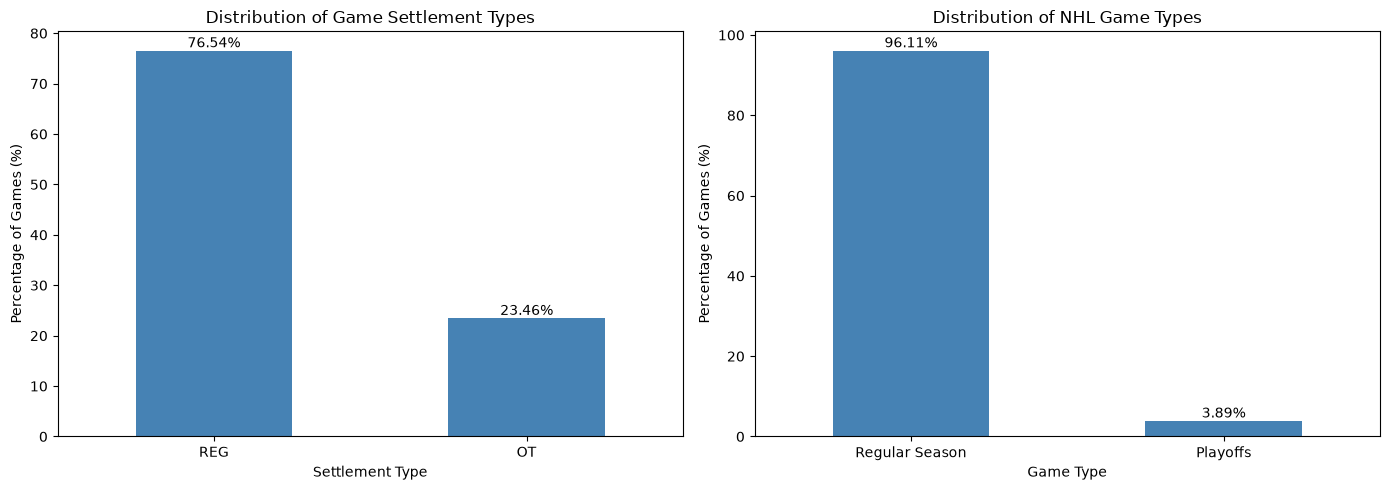

In [44]:
# Calculate percentage distributions
settlement = game_stats_clean["settled_in"].value_counts(normalize=True) * 100
game_types = game_stats_clean["game_type"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Game settlement
settlement.plot(kind="bar", ax=ax[0], color="steelblue", rot=0)
ax[0].set_title("Distribution of Game Settlement Types")
ax[0].set_ylabel("Percentage of Games (%)")
ax[0].set_xlabel("Settlement Type")
ax[0].bar_label(ax[0].containers[0], fmt="%.2f%%")

# Game types
game_types.plot(kind="bar", ax=ax[1], color="steelblue", rot=0)
ax[1].set_title("Distribution of NHL Game Types")
ax[1].set_ylabel("Percentage of Games (%)")
ax[1].set_xlabel("Game Type")
ax[1].bar_label(ax[1].containers[0], fmt="%.2f%%")

plt.tight_layout()
plt.show()

76.54% of games ended in regulation time, while 23.46% were classified as overtime, which appears to includes shootouts. Regular-season games account for 96.11% of observations, with only 3.89% for playoff games. The difference in sample sizes and limited coverage for playoff games will need to be considered when we begin to analyze regular-season performance and playoff success. 

## 7. Grouped Analysis

**7.1 Home Advantage by Team**

**7.2 Regular-Season vs. Playoff Performance**

**7.3 Offensive and Defensive Performance by Team**